# Regression

### California Housing Dataset Description

| Variable Name | Type | Description |
| :--- | :--- | :--- |
| **MedInc** | Feature | Median income in block group [Chicago CAPP]. |
| **HouseAge** | Feature | Median house age in block group [Chicago CAPP]. |
| **AveRooms** | Feature | Average number of rooms per household [Chicago CAPP]. |
| **AveBedrms** | Feature | Average number of bedrooms per household [Chicago CAPP]. |
| **Population** | Feature | Block group population [Chicago CAPP]. |
| **AveOccup** | Feature | Average number of household members [Chicago CAPP]. |
| **Latitude** | Feature | Block group latitude [Chicago CAPP]. |
| **Longitude** | Feature | Block group longitude [Chicago CAPP]. |
| **MedHouseVal** | Target | Median house value for California districts (scaled in \$100,000s) [Chicago CAPP]. |


## Import Libraries 

In [ ]:
!pip install -U scikit-learn

In [28]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.neighbors import KNeighborsRegressor
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score, root_mean_squared_error

### 1. Import Dataset

In [2]:
df = pd.read_csv("House_Price.csv")

### 2. Clean Missing Values

In [3]:
#missing values
df.isnull().sum()

MedInc         0
HouseAge       0
AveRooms       0
AveBedrms      0
Population     0
AveOccup       0
Latitude       0
Longitude      0
MedHouseVal    0
dtype: int64

### 3. EDA

In [4]:
df.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
0,8.3252,41,6.984127,1.023810,322,2.555556,37.88,-122.23,4.526
1,8.3014,21,6.238137,0.971880,2401,2.109842,37.86,-122.22,3.585
2,7.2574,52,8.288136,1.073446,496,2.802260,37.85,-122.24,3.521
3,5.6431,52,5.817352,1.073059,558,2.547945,37.85,-122.25,3.413
4,3.8462,52,6.281853,1.081081,565,2.181467,37.85,-122.25,3.422


In [5]:
df.describe()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude,MedHouseVal
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000
mean,3.870671,28.639486,5.429000,1.096675,1425.476744,3.070655,35.631861,-119.569704,2.068558
std,1.899822,12.585558,2.474173,0.473911,1132.462122,10.386050,2.135952,2.003532,1.153956
min,0.499900,1.000000,0.846154,0.333333,3.000000,0.692308,32.540000,-124.350000,0.149990
25%,2.563400,18.000000,4.440716,1.006079,787.000000,2.429741,33.930000,-121.800000,1.196000
50%,3.534800,29.000000,5.229129,1.048780,1166.000000,2.818116,34.260000,-118.490000,1.797000
75%,4.743250,37.000000,6.052381,1.099526,1725.000000,3.282261,37.710000,-118.010000,2.647250
max,15.000100,52.000000,141.909091,34.066667,35682.000000,1243.333333,41.950000,-114.310000,5.000010


In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 9 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   MedInc       20640 non-null  float64
 1   HouseAge     20640 non-null  int64  
 2   AveRooms     20640 non-null  float64
 3   AveBedrms    20640 non-null  float64
 4   Population   20640 non-null  int64  
 5   AveOccup     20640 non-null  float64
 6   Latitude     20640 non-null  float64
 7   Longitude    20640 non-null  float64
 8   MedHouseVal  20640 non-null  float64
dtypes: float64(7), int64(2)
memory usage: 1.4 MB


<Axes: >

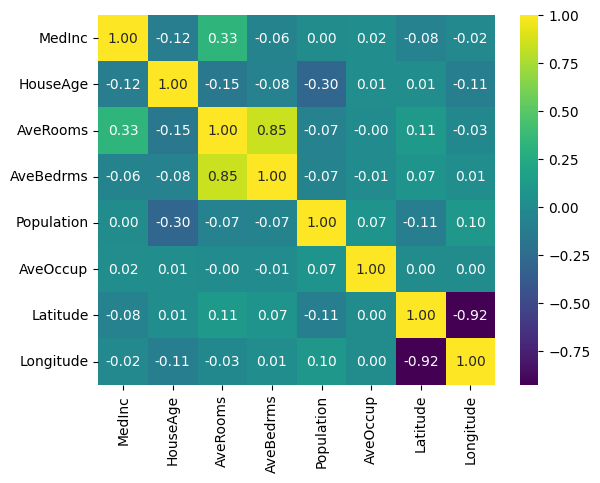

In [8]:
#correlation matrix
cor = df[["MedInc", "HouseAge", "AveRooms", "AveBedrms", "Population", "AveOccup", "Latitude", "Longitude"]].corr()
sns.heatmap(cor, annot= True, fmt = ".2f", cmap = "viridis")

#### 4. Features and Target

In [9]:
X = df.iloc[:,:-1] #features
y = df.iloc[:,-1] #target

-------
------

#### A. Gradient Descent

In [11]:
#Train and Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.33, random_state=42)
#model
model = LinearRegression()
Gradient = model.fit(X_train, y_train)

### B. KNN

In [36]:
#Train and Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.33, random_state=42)
#model
model = KNeighborsRegressor(n_neighbors=20)
KNN = model.fit(X_train, y_train)

### C. Ridge

In [37]:
#Train and Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.33, random_state=42)
#model
model = Ridge(alpha=0.05)
ridge_model = model.fit(X_train, y_train)

### D. Lasso

In [38]:
#Train and Split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.33, random_state=42)
#model
model = Lasso(alpha=0.05)
lasso_model = model.fit(X_train, y_train)

**Compare Models**

In [39]:
models = [Gradient, KNN, lasso_model, ridge_model]
names = [
    "Gradient Descent",
    "K-Nearest Neighbors",
    "Lasso Regression",
    "Ridge Regression",
]

results = []

# Loop through each model to calculate metrics
for name, model in zip(names, models):
    preds = model.predict(X_test)

    results.append(
        {
            "Model": name,
            "MSE": round(mean_squared_error(y_test, preds), 4),
            "MAE": round(mean_absolute_error(y_test, preds), 4),
            "R-squared": round(r2_score(y_test, preds), 2),
            "RMSE": round(root_mean_squared_error(y_test,preds),3)
        }
    )

# Create and display the table
df_table = pd.DataFrame(results)

In [40]:
df_table

,Model,MSE,MAE,R-squared,RMSE
0,Gradient Descent,0.5370,0.5296,0.60,0.733
1,K-Nearest Neighbors,1.1854,0.8475,0.11,1.089
2,Lasso Regression,0.5569,0.5499,0.58,0.746
3,Ridge Regression,0.5370,0.5296,0.60,0.733


## 5. Predict Unkown Values

In [17]:
dt = pd.read_csv("House_Price _un.csv")

In [18]:
dt.head()

,MedInc,HouseAge,AveRooms,AveBedrms,Population,AveOccup,Latitude,Longitude
0,4.0391,33,5.196141,1.035370,580,1.864952,34.16,-118.44
1,3.7105,22,4.083607,1.113115,2237,1.833607,34.16,-118.45
2,3.2386,21,4.578723,1.121277,996,2.119149,34.17,-118.45
3,4.3333,33,4.711246,1.044073,1388,2.109422,34.17,-118.45
4,4.1875,24,4.538710,1.088710,1463,2.359677,34.17,-118.46


In [20]:
house_predictions = ridge_model.predict(dt)

In [21]:
house_predictions

array([2.29433314, 2.24368405, 1.96513302, 2.49041689, 2.39893321,
       1.95746281, 2.47997867])

In [24]:
house_predictions_gr = Gradient.predict(dt)

In [25]:
house_predictions_gr

array([2.29433123, 2.24370772, 1.96514449, 2.49042722, 2.39895071,
       1.95747611, 2.47997932])

In [26]:
house_predictions_knn = KNN.predict(dt)

In [27]:
house_predictions_knn

array([2.16666667, 2.281     , 1.461     , 1.77666667, 2.72      ,
       2.15533333, 2.22666667])

In [47]:
x = float(input("Enter Hours Number"))
y = 1 / (1+ np.exp(-x))
print(y)

Enter Hours Number -25


1.3887943864771144e-11
